Name: Keerthi N

Registration No: 2411021240024

University: Alliance University

Subject: Deep Learning

Topic: Optimizer Comparison Using a Neural Network


# Project 9: Optimizer Comparison Using a Neural Network

## Objective
The objective of this project is to build a simple neural network using the Iris classification dataset and compare the performance of two optimization algorithms: Stochastic Gradient Descent (SGD) and Adam.

## Tasks
1. Load and prepare the Iris dataset.
2. Build a simple neural network for classification.
3. Train the neural network using SGD and Adam optimizers.
4. Compare training loss, accuracy, and classification performance.

## Expected Outcome
Understand how SGD and Adam affect the training process and identify which optimizer performs better for this experiment.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!



## 1. Loading the Dataset

The Iris dataset contains 150 flower samples, four numerical input features, and three target classes. Each sample belongs to Setosa, Versicolor, or Virginica.

The dataset is used to train a neural network that predicts the species of a flower based on its measurements.


In [ ]:

# Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Display the dataset
df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = [iris.target_names[i] for i in y]

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nClass names:", iris.target_names)
print("\nNumber of samples:", len(X))


Dataset shape: (150, 5)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Class names: ['setosa' 'versicolor' 'virginica']

Number of samples: 150



## 2. Data Preprocessing

The dataset is divided into training data and testing data. The training data helps the neural network learn patterns, while the testing data evaluates how well it predicts unseen samples.

An 80:20 split is used. Standardization is applied so that all four input features have comparable scales.


In [ ]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])


Training samples: 120
Testing samples: 30
Number of input features: 4



## 3. Building the Neural Network

A feedforward neural network is created using TensorFlow/Keras.

The network contains:
- Input layer: 4 neurons corresponding to the four flower measurements.
- Hidden layer: 16 neurons with ReLU activation.
- Output layer: 3 neurons corresponding to the three Iris species.

The output layer uses softmax activation to produce class probabilities. The same architecture will be used for both optimizers so that their performance can be compared fairly.


In [ ]:

def build_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax")
    ])

    return model

print("Neural network architecture defined successfully!")


Neural network architecture defined successfully!



## 4. Training with Different Optimizers

The neural network is trained twice using the same architecture, dataset split, loss function, and number of epochs.

1. SGD optimizer: Uses gradient descent with a fixed learning rate to update model weights.
2. Adam optimizer: Uses adaptive learning rates based on estimates of the gradients and their squared values.

The loss function is sparse categorical cross-entropy because this is a three-class classification problem with integer class labels.

Training loss and accuracy are recorded for both optimizers.


In [ ]:

# Set the random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Training settings
EPOCHS = 50
BATCH_SIZE = 16
LEARNING_RATE = 0.01

# Build the SGD model
sgd_model = build_model()

# Build the Adam model
adam_model = build_model()

# Give both models the same initial weights
initial_weights = sgd_model.get_weights()
adam_model.set_weights(initial_weights)

# Compile the SGD model
sgd_model.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Compile the Adam model
adam_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train using SGD
print("Training with SGD...")
sgd_history = sgd_model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0
)

# Train using Adam
print("Training with Adam...")
adam_history = adam_model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0
)

print("\nBoth models have finished training!")


Training with SGD...
Training with Adam...

Both models have finished training!



## 5. Comparing Training Performance

The training loss and training accuracy of SGD and Adam are compared over 50 epochs.

Loss curves help us understand how quickly the optimizers reduce prediction errors. Accuracy curves show how the models' performance changes during training.


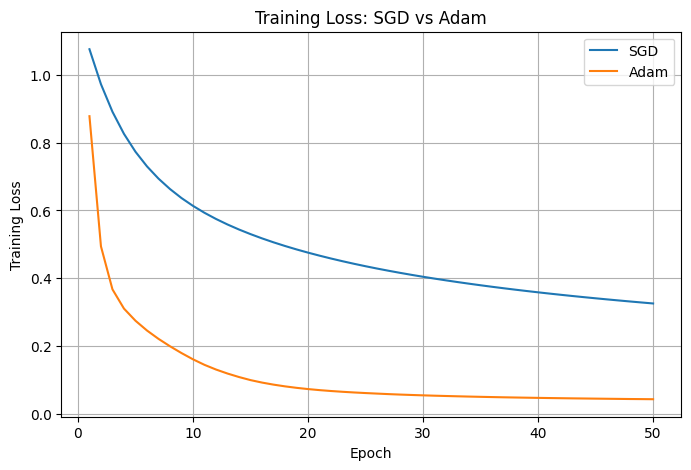

In [ ]:

epochs_range = range(1, EPOCHS + 1)

# Compare training loss
plt.figure(figsize=(8, 5))
plt.plot(
    epochs_range,
    sgd_history.history["loss"],
    label="SGD"
)
plt.plot(
    epochs_range,
    adam_history.history["loss"],
    label="Adam"
)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()



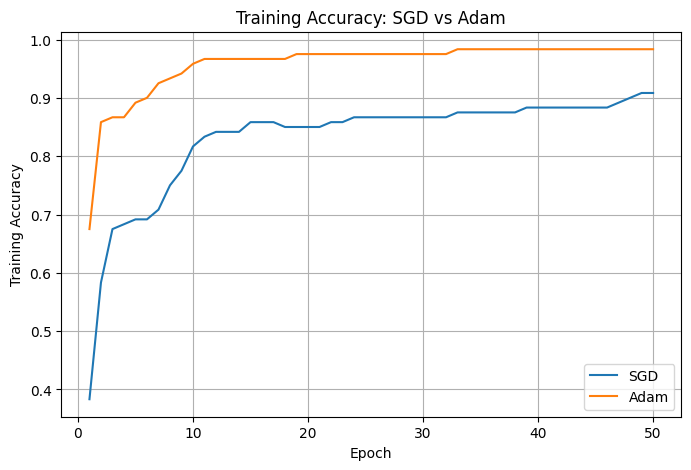

In [ ]:
# Compare training accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    epochs_range,
    sgd_history.history["accuracy"],
    label="SGD"
)
plt.plot(
    epochs_range,
    adam_history.history["accuracy"],
    label="Adam"
)
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()



## 6. Model Evaluation

Both trained models are evaluated on the same unseen test dataset.

The following metrics are used:
- Test loss: Measures prediction error on test data.
- Test accuracy: Measures the percentage of correct test predictions.
- Precision: Measures how many predicted instances of a class are correct.
- Recall: Measures how many actual instances of a class are identified correctly.
- F1-score: Combines precision and recall into one metric.

A confusion matrix is also used to show correct and incorrect predictions for each species.


In [ ]:

# Evaluate both models on the test data
sgd_loss, sgd_test_accuracy = sgd_model.evaluate(
    X_test, y_test, verbose=0
)

adam_loss, adam_test_accuracy = adam_model.evaluate(
    X_test, y_test, verbose=0
)

# Generate predictions
sgd_predictions = np.argmax(
    sgd_model.predict(X_test, verbose=0),
    axis=1
)

adam_predictions = np.argmax(
    adam_model.predict(X_test, verbose=0),
    axis=1
)

# Create comparison table
results = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Test Loss": [sgd_loss, adam_loss],
    "Test Accuracy (%)": [
        sgd_test_accuracy * 100,
        adam_test_accuracy * 100
    ]
})

print("Optimizer Performance Comparison")
display(results.round(4))

# Print classification reports
print("\nSGD Classification Report")
print(classification_report(
    y_test,
    sgd_predictions,
    target_names=iris.target_names,
    zero_division=0
))

print("\nAdam Classification Report")
print(classification_report(
    y_test,
    adam_predictions,
    target_names=iris.target_names,
    zero_division=0
))


Optimizer Performance Comparison


,Optimizer,Test Loss,Test Accuracy (%)
0,SGD,0.3724,83.3333
1,Adam,0.0663,96.6667



SGD Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.86      0.60      0.71        10
   virginica       0.69      0.90      0.78        10

    accuracy                           0.83        30
   macro avg       0.85      0.83      0.83        30
weighted avg       0.85      0.83      0.83        30


Adam Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30




## 7. Confusion Matrix Comparison

A confusion matrix compares the actual flower species with the species predicted by the model. The diagonal entries represent correct predictions, while the off-diagonal entries represent misclassifications.


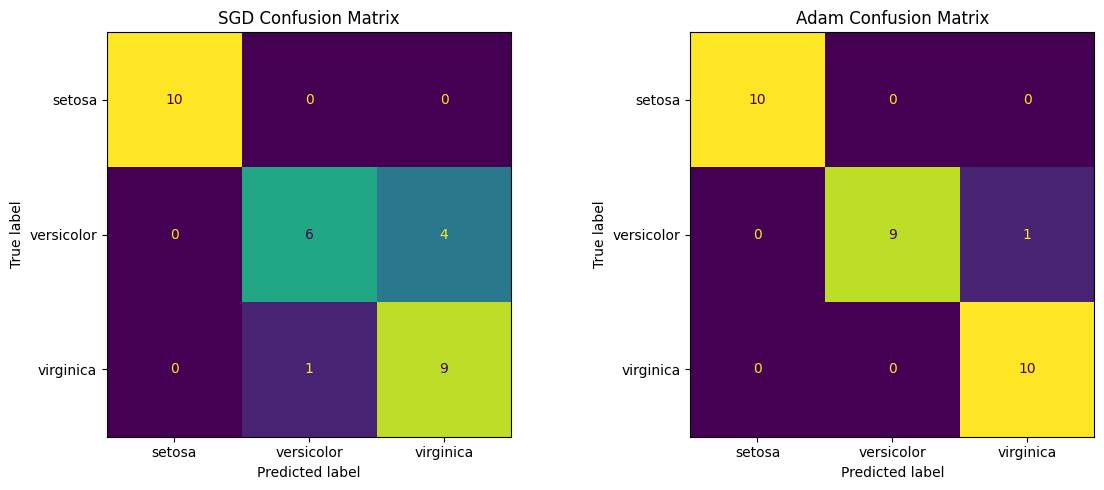

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, optimizer_name in [
    (axes[0], sgd_predictions, "SGD"),
    (axes[1], adam_predictions, "Adam")
]:
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1, 2]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=iris.target_names
    )

    display_matrix.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{optimizer_name} Confusion Matrix")

plt.tight_layout()
plt.show()



## 8. Final Comparison and Observation

The final comparison uses the test accuracy and test loss of both optimizers. The optimizer with the higher test accuracy is considered better according to test accuracy for this particular experiment. Test loss is also considered to provide a more complete comparison.


In [ ]:

print("FINAL OBSERVATIONS")
print("-" * 40)

print(f"SGD Test Accuracy:  {sgd_test_accuracy * 100:.2f}%")
print(f"Adam Test Accuracy: {adam_test_accuracy * 100:.2f}%")

print(f"SGD Test Loss:  {sgd_loss:.4f}")
print(f"Adam Test Loss: {adam_loss:.4f}")

if sgd_test_accuracy > adam_test_accuracy:
    print("\nSGD achieved higher test accuracy in this experiment.")
elif adam_test_accuracy > sgd_test_accuracy:
    print("\nAdam achieved higher test accuracy in this experiment.")
else:
    print("\nBoth optimizers achieved the same test accuracy.")

if sgd_loss < adam_loss:
    print("SGD achieved lower test loss.")
elif adam_loss < sgd_loss:
    print("Adam achieved lower test loss.")
else:
    print("Both optimizers achieved the same test loss.")

print("\nConclusion:")
print(
    "The comparison shows how the choice of optimizer "
    "can affect neural network training and classification."
)


FINAL OBSERVATIONS
----------------------------------------
SGD Test Accuracy:  83.33%
Adam Test Accuracy: 96.67%
SGD Test Loss:  0.3724
Adam Test Loss: 0.0663

Adam achieved higher test accuracy in this experiment.
Adam achieved lower test loss.

Conclusion:
The comparison shows how the choice of optimizer can affect neural network training and classification.



## 9. Conclusion

In this project, a simple neural network was implemented using the Iris dataset to classify three species of flowers. The model was trained using two optimization algorithms: Stochastic Gradient Descent (SGD) and Adam.

The training loss, training accuracy, test accuracy, classification reports, and confusion matrices were compared to understand the behavior of both optimizers.

The experiment demonstrates that optimizer selection can influence the speed of learning, the reduction in loss, and classification performance. Adam adapts its updates using gradient information, whereas SGD uses gradient descent with a fixed learning rate in this implementation.

The better optimizer for this experiment was identified using the observed test accuracy and test loss. The results are specific to the selected model, dataset split, learning rate, and number of epochs.
